# 02. Камера, дискретизация и шум

Курс «От интерференции до измерения поверхности». [Маршрут](README.md).

**Цели:** понять, какая информация теряется ещё до запуска алгоритма и почему контраст не равен точности.

Работайте сверху вниз, затем меняйте параметры и выполняйте **Restart Kernel → Run All**.
Все численные примеры учебные: они объясняют метод, а не подтверждают точность прибора.
Рекомендуемый темп: одна тетрадь за занятие, с собственными записями и упражнениями.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage, signal, interpolate, optimize

course_dir = next(p for p in [Path.cwd(), Path.cwd()/"notes"/"interferometry-course"]
                  if (p/"course_lib.py").exists())
if str(course_dir) not in sys.path:
    sys.path.insert(0, str(course_dir))
import course_lib as cl
np.set_printoptions(precision=5, suppress=True)

## 1. Пиксель измеряет среднее по площади

Пиксель не является математической точкой. Он интегрирует интенсивность по площади
и времени. Для одномерной синусоиды $I(x)=a+b\cos(2\pi fx+\phi_0)$ и пикселя ширины p:

$$I_j=\frac1p\int_{x_j-p/2}^{x_j+p/2}I(x)dx
=a+b\operatorname{sinc}(fp)\cos(2\pi fx_j+\phi_0),$$
где $\operatorname{sinc}(u)=\sin(\pi u)/(\pi u)$.
Так пиксель снижает модуляцию ещё до квантования. В 2D множители по X,Y перемножаются
для прямоугольного пикселя. Добавляются оптическое размытие и функция передачи объектива.

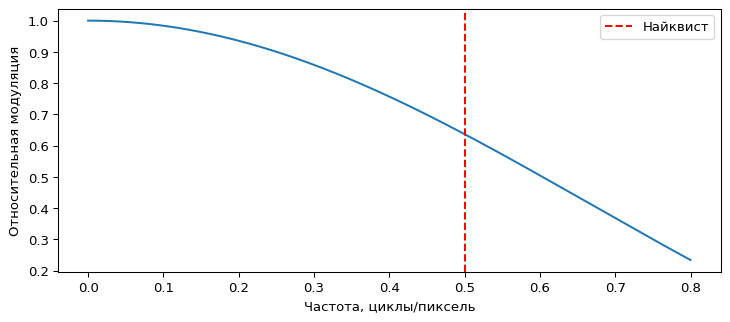

In [2]:
frequency = np.linspace(0,.8,400)  # cycles/pixel
plt.plot(frequency,np.abs(np.sinc(frequency)))
plt.axvline(.5,color='r',ls='--',label='Найквист')
plt.xlabel('Частота, циклы/пиксель'); plt.ylabel('Относительная модуляция')
plt.legend(); plt.show()

## 2. Найквист — необходимое условие, а не запас качества

После выборки на целых j частоты f и f+k неразличимы для целого k.
Для вещественного косинуса частоты f и 1−f тоже дают одинаковые отсчёты при нулевой
начальной фазе. Поэтому |f|<1/2 цикла на пиксель — граница восстановления полосы
частот. Ровно два отсчёта на период — крайне плохой режим для измерения фазы.

Значение имеет **максимальная локальная** частота, то есть градиент полной фазы,
а не только средний период. Интерполяция картинки не возвращает утраченные отсчёты.

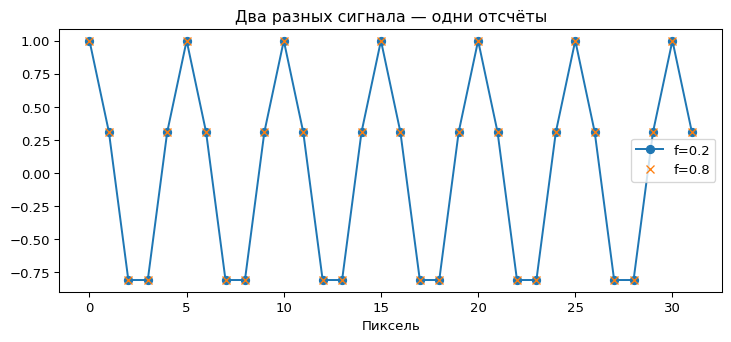

In [3]:
j=np.arange(32)
y1=np.cos(2*np.pi*.2*j)
y2=np.cos(2*np.pi*.8*j)
assert np.allclose(y1,y2,atol=1e-12)
plt.plot(j,y1,'o-',label='f=0.2'); plt.plot(j,y2,'x',label='f=0.8')
plt.xlabel('Пиксель'); plt.legend(); plt.title('Два разных сигнала — одни отсчёты'); plt.show()

## 3. Шумы и нелинейность камеры

Для числа фотоэлектронов $K\sim\mathrm{Poisson}(\mu)$: среднее и дисперсия равны μ.
Относительный фотонный шум убывает как $1/\sqrt\mu$. Шум считывания добавляет
приблизительно постоянную дисперсию $\sigma_r^2$ в электронах. После перевода в
нормированную яркость дисперсия примерно $I/P+\sigma_r^2/P^2$, где P — масштаб экспозиции.

Квантование в B бит даёт шаг $\Delta=1/(2^B-1)$; оценка дисперсии Δ²/12 требует
достаточно «случайного» положения сигнала внутри кванта и не универсальна.
Насыщение обрезает синусоиду, создаёт гармоники и нарушает модель PSI.
Гамма-корректированное JPEG-изображение не является линейным измерением интенсивности.

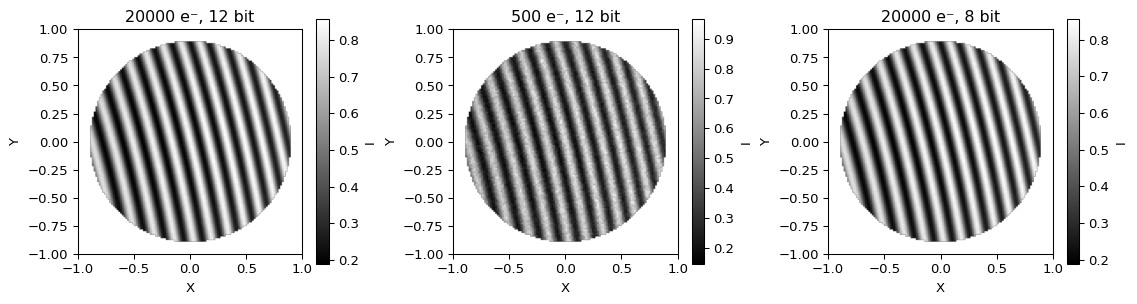

RMS ошибки яркости: 0.005107481267028467
RMS ошибки яркости: 0.033229933717827384
RMS ошибки яркости: 0.005237641646458625


In [4]:
s=cl.scene(n=128)
images=[cl.camera(s['image'],photons=P,bits=B,seed=4) for P,B in [(20000,12),(500,12),(20000,8)]]
cl.show_maps(images,['20000 e⁻, 12 bit','500 e⁻, 12 bit','20000 e⁻, 8 bit'],s['mask'],cmap='gray',units='I')
for image in images:
    print('RMS ошибки яркости:',np.std((image-s['image'])[s['mask']]))

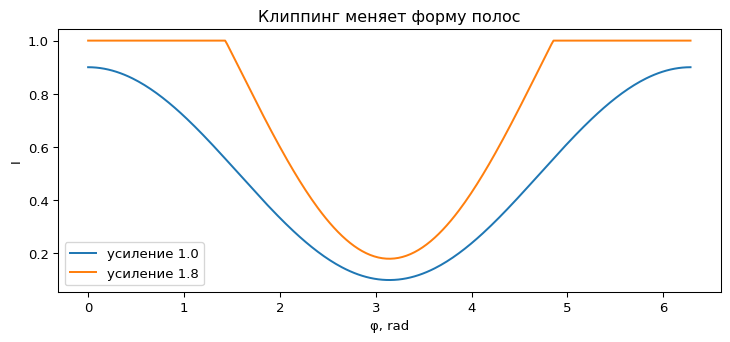

In [5]:
t=np.linspace(0,2*np.pi,300)
fig,ax=plt.subplots()
for gain in [1.,1.8]:
    values=np.clip(gain*(.5+.4*np.cos(t)),0,1)
    ax.plot(t,values,label=f'усиление {gain}')
ax.set(xlabel='φ, rad',ylabel='I',title='Клиппинг меняет форму полос'); ax.legend(); plt.show()

## 4. Апертуры, тени и спекл

Апертура — область, где измерение физически допустимо. Чёрный пиксель за апертурой
не означает нулевую фазу. Храните отдельно значения и булеву маску.
Сглаживание у границы можно выполнять нормированной свёрткой:
$I_{smooth}=(G*(MI))/(G*M)$, где M — маска. Иначе чёрный фон сдвигает экстремумы.

У шероховатой поверхности поле в пикселе может быть суммой множества комплексных
вкладов. Наблюдаемая фаза такого поля не всегда равна фазе единственной высоты
геометрической поверхности в центре пикселя. Простейшая модель шума яркости этого
не описывает. Для ИК-стенда нужны реальные серии и отдельное исследование спекла,
пространственного разрешения и устойчивости поля между кадрами.

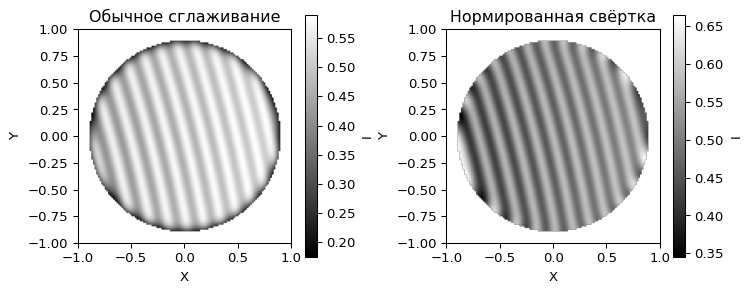

In [6]:
mask=s['mask']; raw=np.where(mask,s['image'],0)
ordinary=ndimage.gaussian_filter(raw,3)
weight=ndimage.gaussian_filter(mask.astype(float),3)
normalized=ndimage.gaussian_filter(raw,3)/np.maximum(weight,1e-12)
cl.show_maps([ordinary,normalized],['Обычное сглаживание','Нормированная свёртка'],mask,cmap='gray',units='I')

## Задания

1. Сколько пикселей на период имеют частоты 0.1 и 0.45 cycles/pixel?
2. Увеличьте экспозицию в 4 раза без насыщения. Во сколько раз уменьшится относительный фотонный шум?
3. Почему изображение с хорошим визуальным контрастом может давать плохую фазу?
4. Проверьте разность обычного и нормированного сглаживания вдали от границы.

<details><summary>Разбор</summary>

1. 10 и примерно 2.22. 2. Вдвое. 3. Возможны клиппинг, алиасинг, нелинейность,
спекл и несовпадение кадров. 4. Там G*M≈1 и результаты почти совпадают.
</details>

**В проекте:** `Bitmap` и ABI плагинов сейчас 8-битные. Это ограничение формата
данных, а не фундаментальное требование интерферометрии.
Далее: [трассировка](03_fringe_tracing.ipynb).